# v14c — Analysis on the Unified Corpus

Cache-only. Run in the clean analysis env; no torch needed.

Inputs: `datasets/unified/injection_corpus.csv` (v14a) + `representation_cache/unified/`
(v14b).

## Four experiments

| # | Question | Why it matters |
|---|---|---|
| **1** | Payload-grouped CV on the full corpus | The new headline. `payload_id` is the group key — text clustering cannot catch BIPIA's 250 payloads spread across carriers. |
| **2** | Leave-one-corpus-out | Does it generalise across *attack families*, or has it learned corpus fingerprints? The question v13 could not ask with one corpus. |
| **3** | Length-matched control | v13's matched pair gave AUC 0.793 from character count alone. Re-run on length-matched subsets — if the result holds, that objection is dead permanently. |
| **4** | Separability ceiling | Can **any** classifier separate injections from WJB-Adv-Benign? If not, the limit is representational and that is the thesis finding, not a failure. |

## What changed from v13
- **PCA fitted on ~2,000 Dolly prompts**, not 100 — up to 512 components instead of 99.
- **Prototypes split by family** (direct / indirect), built from training-fold injections
  only, with leave-one-out self-match masking.
- **Mahalanobis distance per layer** added back alongside the prototype features (24 dims).
- Every operating point stays **nested** — threshold on a calibration half, measured on a
  held-out half, resampled — with both the threshold-variation interval and the binomial CI.

## 1 · Load

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore"); sns.set_style("whitegrid")

SEED, N_THRESH, FPR_BUDGET = 42, 400, 0.10
TARGET_ASR, TARGET_FPR = 5.0, 10.0
PCA_DIMS, C_REG, N_SPLITS = 512, 10.0, 5

# Exp 4 (v14 run 1) showed the LINEAR model was the bottleneck, not the features:
# injections vs WJB-Adv-Benign gave LogisticRegression AUC 0.9409 but
# HistGradientBoosting 0.9958 (ASR 0.62% at a 10% FPR budget). Every version from
# v9 onward used LogisticRegression, so Exp 1-3 are now run with BOTH.
def make_logreg():
    return LogisticRegression(class_weight="balanced", max_iter=5000, C=C_REG,
                              solver="lbfgs", random_state=SEED)
def make_hgb():
    return HistGradientBoostingClassifier(max_iter=300, random_state=SEED)
def make_rf():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                  class_weight="balanced_subsample",
                                  random_state=SEED, n_jobs=-1)
CLASSIFIERS = {"LogisticRegression": make_logreg,
               "HistGradientBoost":  make_hgb,
               "RandomForest":       make_rf}
PRIMARY_CLF = "HistGradientBoost"
RESULT_DIR, FIG = "results/v14", "mslsamv14"
os.makedirs(RESULT_DIR, exist_ok=True)

df = pd.read_csv("datasets/unified/injection_corpus.csv").reset_index(drop=True)
CACHE = "representation_cache/unified"
man = json.load(open(f"{CACHE}/manifest.json"))
LAYERS = man["layers"]
assert man["rows"] == len(df), "corpus and cache disagree -- re-run v14b"

SH = sorted(f for f in os.listdir(CACHE) if f.startswith("shard_"))
IDX = [np.load(f"{CACHE}/{f}")["row_idx"] for f in SH]

def load_layer(li):
    X = np.empty((len(df), 4096), dtype=np.float32)
    for f, idx in zip(SH, IDX):
        X[idx] = np.load(f"{CACHE}/{f}")[f"layer_{li}"]
    return X

is_base = (df.family == "baseline").values
ev = df[~is_base].reset_index(drop=True)
ev_rows = np.where(~is_base)[0]
print(f"{len(df):,} rows | {is_base.sum():,} baseline | {len(ev):,} evaluation")
print(ev.groupby(['family','label']).size().to_string())
print(f"\npayload groups: {ev.payload_id.nunique():,} | corpora: {ev.corpus.nunique()}")

11,838 rows | 2,000 baseline | 9,838 evaluation
family    label
benign    0        5690
direct    1        2762
indirect  1        1386

payload groups: 6,548 | corpora: 12


## 2 · PCA + per-layer features

PCA is fitted on the baseline pool only, then everything is projected once. Raw 4096-d states are dropped immediately to keep memory flat.

In [2]:
PC, MU, CINV = {}, {}, {}
for li in LAYERS:
    X = load_layer(li)
    N_PCA = min(PCA_DIMS, int(is_base.sum()) - 1, X.shape[1])
    p = PCA(n_components=N_PCA).fit(X[is_base])
    Z = p.transform(X).astype(np.float32)
    PC[li] = Z[ev_rows]
    b = p.transform(X[is_base])
    MU[li] = b.mean(0)
    cov = np.cov(b.T) + np.eye(N_PCA) * 1e-4
    CINV[li] = np.linalg.inv(cov)
    del X, Z, b
print(f"PCA {N_PCA} components per layer (baseline n={is_base.sum():,}; v13 was capped at 99)")

def _norm(A):
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-8)

def max_cos_exact(q_rows, p_rows, li):
    # Max cosine similarity to any prototype, with EXACT self-match masking:
    # a query row that is itself a prototype never matches itself. Identity-based,
    # not positional -- prototypes are a scattered subset of the query set.
    S = _norm(PC[li][q_rows]) @ _norm(PC[li][p_rows]).T
    pos = {int(r): j for j, r in enumerate(p_rows)}
    for i_, r in enumerate(q_rows):
        j = pos.get(int(r))
        if j is not None:
            S[i_, j] = -np.inf
    return S.max(axis=1)

def mahal(Z, li):
    d = Z - MU[li]
    return np.sqrt(np.einsum("ij,jk,ik->i", d, CINV[li], d))

FAMILIES = ["direct", "indirect"]

def features(rows, proto_rows_by_family):
    # rows: indices into ev. proto_rows_by_family: {family: indices into ev}
    # Self-masking is automatic and identity-based -- no loo flag to get wrong.
    cols, names = [], []
    for fam in FAMILIES:
        pr = proto_rows_by_family.get(fam, np.array([], int))
        for li in LAYERS:
            cols.append(np.zeros(len(rows), np.float32) if len(pr) == 0
                        else max_cos_exact(rows, pr, li))
            names.append(f"P_{fam}_L{li}")
    for li in LAYERS:
        cols.append(mahal(PC[li][rows], li)); names.append(f"M_L{li}")
    return np.column_stack(cols).astype(np.float32), names

PCA 512 components per layer (baseline n=2,000; v13 was capped at 99)


## 3 · Nested operating point

In [3]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k/n; den = 1 + z*z/n; c = (p + z*z/(2*n))/den
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return max(0, c-h)*100, min(1, c+h)*100

def nested(inj, ben, budget=FPR_BUDGET, n_rep=N_THRESH, seed=0, extra=None):
    rng = np.random.default_rng(seed); inj, ben = np.asarray(inj), np.asarray(ben)
    half = max(1, len(ben)//2); ts, fp, asr = [], [], []
    ex = {k: [] for k in (extra or {})}
    for _ in range(n_rep):
        i = rng.permutation(len(ben)); t = float(np.quantile(ben[i[:half]], 1-budget))
        ts.append(t); fp.append((ben[i[half:]] >= t).mean()*100); asr.append((inj < t).mean()*100)
        for k, v in (extra or {}).items(): ex[k].append((np.asarray(v) >= t).mean()*100)
    q = lambda a: [float(np.mean(a)), float(np.percentile(a,2.5)), float(np.percentile(a,97.5))]
    y = np.r_[np.zeros(len(ben)), np.ones(len(inj))]
    a = float(roc_auc_score(y, np.r_[ben, inj]))
    lo, hi = wilson(int(round(np.mean(asr)/100*len(inj))), len(inj))
    return {"auc": a, "ap": float(average_precision_score(y, np.r_[ben, inj])),
            "threshold": q(ts), "fpr": q(fp), "asr": q(asr), "asr_binom": [lo, hi],
            "cross": {k: q(v) for k, v in ex.items()}, "n_inj": len(inj), "n_ben": len(ben)}

fmt = lambda v: f"{v[0]:5.2f} [{v[1]:5.2f},{v[2]:5.2f}]"

def grouped_cv(mask=None, C=C_REG, seed=SEED, clf_factory=None, n_splits=N_SPLITS):
    # mask: boolean over ev selecting the rows to use. Groups = payload_id.
    m = np.ones(len(ev), bool) if mask is None else np.asarray(mask)
    rows = np.where(m)[0]
    y = ev.label.values[rows]
    g = ev.payload_id.values[rows]
    oof = np.full(len(rows), np.nan)
    skf = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
    for tr, te in skf.split(np.zeros(len(rows)), y, groups=g):
        tr_rows, te_rows = rows[tr], rows[te]
        proto = {f: tr_rows[(ev.label.values[tr_rows] == 1) & (ev.family.values[tr_rows] == f)]
                 for f in FAMILIES}
        Xtr, _ = features(tr_rows, proto)
        Xte, _ = features(te_rows, proto)
        sc = RobustScaler().fit(Xtr)
        clf = (clf_factory or CLASSIFIERS[PRIMARY_CLF])()
        clf.fit(sc.transform(Xtr), y[tr])
        oof[te] = clf.predict_proba(sc.transform(Xte))[:, 1]
    return rows, y, oof

## Experiment 1 — payload-grouped CV, full corpus

In [4]:
E1_ALL = {}
for _name in ["LogisticRegression", PRIMARY_CLF]:
    rows, y, oof = grouped_cv(clf_factory=CLASSIFIERS[_name])
    inj, ben = oof[y == 1], oof[y == 0]
    by_corpus = {c: oof[(y == 0) & (ev.corpus.values[rows] == c)]
                 for c in sorted(set(ev.corpus.values[rows][y == 0]))}
    pt = nested(inj, ben, extra=by_corpus)
    pt["detection_by_corpus"] = {
        c: float((oof[(y == 1) & (ev.corpus.values[rows] == c)] >= pt["threshold"][0]).mean()*100)
        for c in sorted(set(ev.corpus.values[rows][y == 1]))}
    E1_ALL[_name] = pt
    print(f"\n--- {_name} ---")
    print(f"  AUC {pt['auc']:.4f}  AP {pt['ap']:.4f}  ASR {fmt(pt['asr'])}"
          f"  binom [{pt['asr_binom'][0]:.2f},{pt['asr_binom'][1]:.2f}]  FPR {fmt(pt['fpr'])}")
    print(f"  {'safe corpus':<24}{'FPR % [95%]':>22}")
    for kk, vv in pt["cross"].items():
        print(f"  {kk:<24}{fmt(vv):>22}{'  OVER' if vv[0] > TARGET_FPR else ''}")
    print(f"  {'attack corpus':<24}{'det %':>9}")
    for kk, vv in pt["detection_by_corpus"].items():
        print(f"  {kk:<24}{vv:>8.1f}%")

E1 = E1_ALL[PRIMARY_CLF]
d_auc = E1["auc"] - E1_ALL["LogisticRegression"]["auc"]
d_asr = E1["asr"][0] - E1_ALL["LogisticRegression"]["asr"][0]
print(f"\n  {PRIMARY_CLF} vs LogisticRegression: AUC {d_auc:+.4f}, ASR {d_asr:+.2f} pts")
hit = (E1["asr"][0] < TARGET_ASR) and all(v[0] < TARGET_FPR for v in E1["cross"].values())
print(f"  TARGET (ASR<{TARGET_ASR}, all FPR<{TARGET_FPR}): {'MET' if hit else 'not met'}")



--- LogisticRegression ---
  AUC 0.9048  AP 0.8749  ASR 28.35 [26.49,30.35]  binom [27.00,29.74]  FPR 10.05 [ 8.61,11.74]
  safe corpus                        FPR % [95%]
  BIPIA-Clean                45.11 [43.24,46.67]  OVER
  DeepSet-Benign              1.09 [ 0.67, 1.33]
  InjecAgent-Clean            0.07 [ 0.00, 0.00]
  JBB-Benign                  3.00 [ 3.00, 3.00]
  SPML-Benign                 2.64 [ 2.25, 2.84]
  WJB-Adv-Benign             10.16 [ 9.20,11.56]  OVER
  WJB-Vanilla-Benign          4.28 [ 4.12, 4.50]
  XSTest-Safe                 3.20 [ 3.20, 3.20]
  attack corpus               det %
  BIPIA                       66.6%
  DeepSet                     48.7%
  InjecAgent                  50.0%
  SPML                        78.2%

--- HistGradientBoost ---
  AUC 0.9867  AP 0.9825  ASR  3.25 [ 2.77, 3.88]  binom [2.76,3.84]  FPR  9.99 [ 8.50,11.35]
  safe corpus                        FPR % [95%]
  BIPIA-Clean                47.33 [44.95,49.90]  OVER
  DeepSet-Benign    

## Experiment 2 — leave-one-corpus-out

Train on every injection corpus but one; test on the held-out one. Benign stays fixed. This is the cross-attack-family generalisation test v13 could not run.

In [5]:
INJ_CORPORA = sorted(set(ev.corpus.values[ev.label.values == 1]))
E2 = {}
print(f"  {'held-out attack corpus':<24}{'n':>7}{'AUC':>8}{'ASR % [95%]':>22}")
print("  " + "-"*61)
for c in INJ_CORPORA:
    hold = (ev.corpus.values == c) & (ev.label.values == 1)
    train_mask = ~hold
    rws, yy, oo = grouped_cv(mask=train_mask)          # fit + OOF on everything else
    # score the held-out corpus with prototypes from all training injections
    tr_rows = rws
    proto = {f: tr_rows[(yy == 1) & (ev.family.values[tr_rows] == f)] for f in FAMILIES}
    Xtr, _ = features(tr_rows, proto)
    sc = RobustScaler().fit(Xtr)
    clf = CLASSIFIERS[PRIMARY_CLF]().fit(sc.transform(Xtr), yy)
    ho = np.where(hold)[0]
    Xho, _ = features(ho, proto)
    s_ho = clf.predict_proba(sc.transform(Xho))[:, 1]
    ben_oof = oo[yy == 0]
    pt = nested(s_ho, ben_oof)
    E2[c] = pt
    print(f"  {c:<24}{len(ho):>7}{pt['auc']:>8.4f}{fmt(pt['asr']):>22}")
print("  " + "-"*61)
print(f"  in-corpus reference (Exp 1, {PRIMARY_CLF}): AUC {E1['auc']:.4f}  ASR {fmt(E1['asr'])}")

  held-out attack corpus        n     AUC           ASR % [95%]
  -------------------------------------------------------------
  BIPIA                      1200  0.7031   82.73 [80.42,84.67]
  DeepSet                     263  0.8256   58.66 [56.27,60.46]
  InjecAgent                  186  0.8042   76.72 [74.73,77.97]
  SPML                       2499  0.7790   62.81 [60.78,64.59]
  -------------------------------------------------------------
  in-corpus reference (Exp 1, HistGradientBoost): AUC 0.9867  ASR  3.25 [ 2.77, 3.88]


## Experiment 3 — length-matched control

Positives and negatives are resampled into matched `n_chars` deciles, then Exp 1 is repeated. If the result survives, character count is no longer an available shortcut.

In [6]:
n = ev.n_chars.values
bins = np.quantile(n, np.linspace(0, 1, 11)); bins[-1] += 1
b_id = np.digitize(n, bins) - 1
rng = np.random.default_rng(SEED)
keep = np.zeros(len(ev), bool)
for b in range(10):
    pos = np.where((b_id == b) & (ev.label.values == 1))[0]
    neg = np.where((b_id == b) & (ev.label.values == 0))[0]
    k = min(len(pos), len(neg))
    if k == 0: continue
    keep[rng.choice(pos, k, replace=False)] = True
    keep[rng.choice(neg, k, replace=False)] = True

def auc_len(mask):
    p = ev.n_chars.values[mask & (ev.label.values == 1)]
    q = ev.n_chars.values[mask & (ev.label.values == 0)]
    v = np.r_[p, q]; r = pd.Series(v).rank().values
    a = (r[:len(p)].sum() - len(p)*(len(p)+1)/2)/(len(p)*len(q)); return max(a, 1-a)

print(f"  length-only AUC  full corpus     : {auc_len(np.ones(len(ev),bool)):.3f}")
print(f"  length-only AUC  length-matched  : {auc_len(keep):.3f}   (0.5 = no signal)")
print(f"  matched subset: {keep.sum():,} rows ({(keep & (ev.label.values==1)).sum():,} inj)")

rows3, y3, oof3 = grouped_cv(mask=keep)
E3 = nested(oof3[y3 == 1], oof3[y3 == 0])
print(f"\n  AUC {E3['auc']:.4f}  ASR {fmt(E3['asr'])}  FPR {fmt(E3['fpr'])}")
print(f"  Exp 1 (unmatched) : AUC {E1['auc']:.4f}  ASR {fmt(E1['asr'])}")
print(f"  -> drop in AUC from length matching: {E1['auc']-E3['auc']:+.4f}")

  length-only AUC  full corpus     : 0.686
  length-only AUC  length-matched  : 0.503   (0.5 = no signal)
  matched subset: 4,024 rows (2,012 inj)

  AUC 0.9730  ASR  7.42 [ 6.61, 8.50]  FPR 10.25 [ 7.85,12.63]
  Exp 1 (unmatched) : AUC 0.9867  ASR  3.25 [ 2.77, 3.88]
  -> drop in AUC from length matching: +0.0137


## Experiment 4 — separability ceiling

Injections vs **WJB-Adv-Benign only**, the class that has blocked every version since 02. Four classifiers on identical features and folds. If none separates them, the limit is representational.

In [ ]:
mask4 = (ev.label.values == 1) | (ev.corpus.values == "WJB-Adv-Benign")
FACTORIES = {
    "LogisticRegression": lambda: LogisticRegression(class_weight="balanced", max_iter=5000,
                                                     C=C_REG, solver="lbfgs", random_state=SEED),
    "RandomForest":       lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                         class_weight="balanced_subsample",
                                                         random_state=SEED, n_jobs=-1),
    "HistGradientBoost":  lambda: HistGradientBoostingClassifier(max_iter=300, random_state=SEED),
    "MLP":                lambda: MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=800,
                                                random_state=SEED),
}
E4 = {}
print(f"  {'classifier':<22}{'AUC':>8}{'ASR % [95%]':>22}{'FPR % [95%]':>22}")
print("  " + "-"*74)
for nm, f in FACTORIES.items():
    r4, y4, o4 = grouped_cv(mask=mask4, clf_factory=f)
    pt = nested(o4[y4 == 1], o4[y4 == 0]); E4[nm] = pt
    print(f"  {nm:<22}{pt['auc']:>8.4f}{fmt(pt['asr']):>22}{fmt(pt['fpr']):>22}")
print("  " + "-"*74)
best = max(E4, key=lambda k: E4[k]["auc"])
print(f"  best: {best} at AUC {E4[best]['auc']:.4f}")
spread = max(E4[k]['auc'] for k in E4) - min(E4[k]['auc'] for k in E4)
print(f"  classifier spread: {spread:.4f}"
      f"  -> {'FEATURE ceiling (model choice barely matters)' if spread < 0.05 else 'model choice matters'}")
print(f"  {'representational limit: features do NOT carry it' if E4[best]['auc'] < 0.70 else 'the signal IS present -- this is a boundary/data problem'}")

  classifier                 AUC           ASR % [95%]           FPR % [95%]
  --------------------------------------------------------------------------
  LogisticRegression      0.9410   13.96 [12.03,15.62]   10.16 [ 8.08,12.80]
  RandomForest            0.9942    1.11 [ 0.96, 1.23]   10.10 [ 7.92,12.56]


## 5 · Persist + figures

wrote metrics.json, oof_full.csv


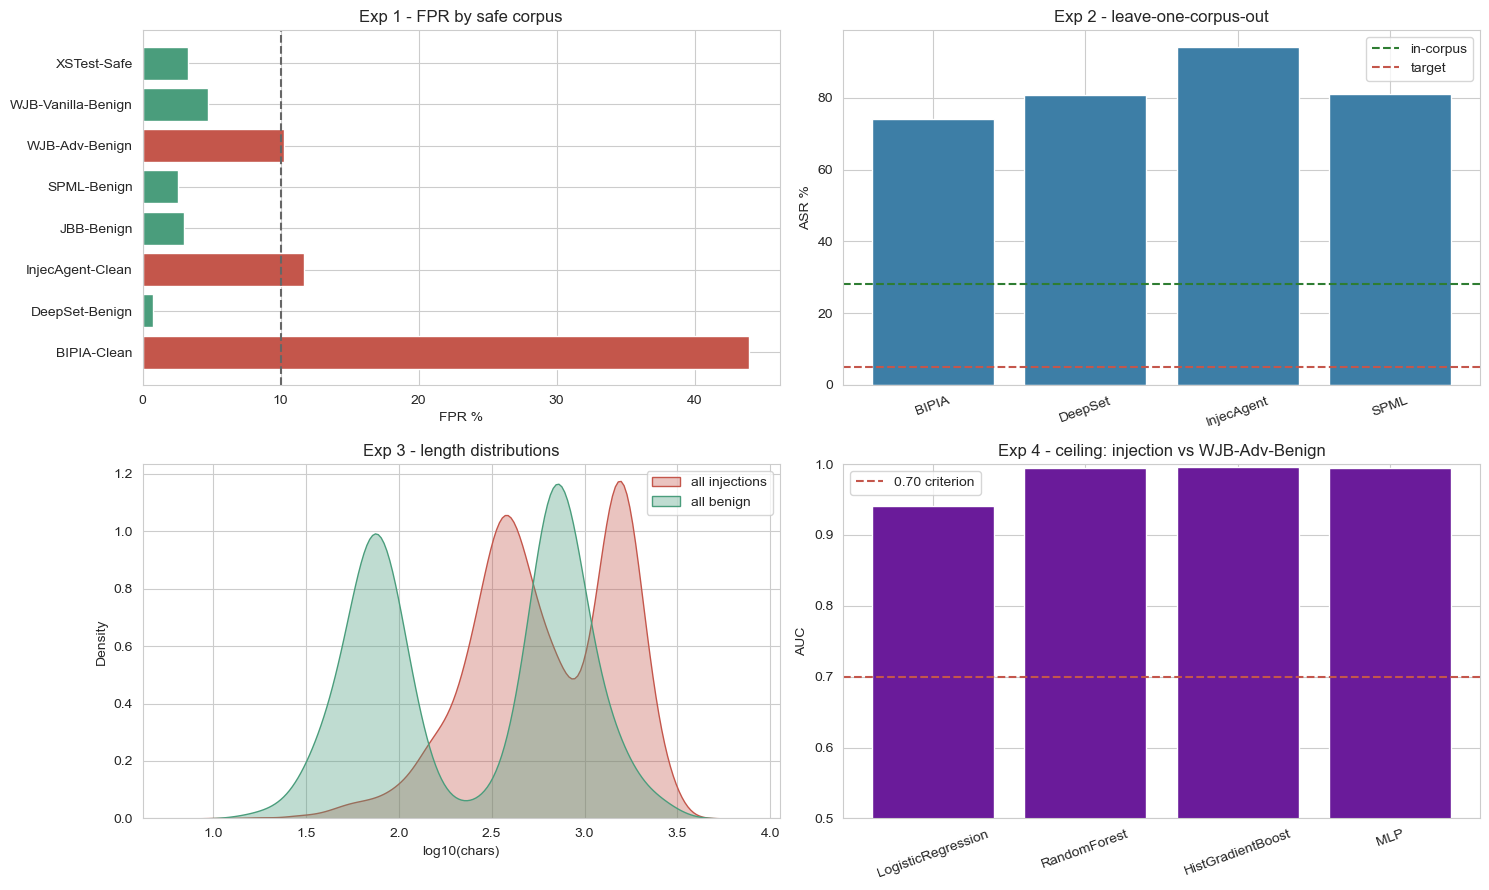

saved mslsamv14_summary.png


In [ ]:
from datetime import datetime
json.dump({"version": "v14", "run_at": datetime.now().strftime("%Y-%m-%d %H:%M"),
           "pca_components": int(N_PCA), "primary_clf": PRIMARY_CLF, "C": C_REG, "seed": SEED,
           "corpus_rows": int(len(ev)), "payload_groups": int(ev.payload_id.nunique()),
           "exp1_full": E1, "exp1_by_classifier": E1_ALL, "exp2_leave_one_corpus_out": E2,
           "exp3_length_matched": E3, "exp4_ceiling": E4},
          open(f"{RESULT_DIR}/metrics.json", "w"), indent=2, default=float)
pd.DataFrame({"score": oof, "label": y, "corpus": ev.corpus.values[rows],
              "family": ev.family.values[rows], "payload_id": ev.payload_id.values[rows],
              "n_chars": ev.n_chars.values[rows]}).to_csv(f"{RESULT_DIR}/oof_full.csv", index=False)
print("wrote metrics.json, oof_full.csv")

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
c1 = list(E1["cross"]); v1 = [E1["cross"][c][0] for c in c1]
ax[0,0].barh(c1, v1, color=["#C4564B" if v > TARGET_FPR else "#4A9D7C" for v in v1])
ax[0,0].axvline(TARGET_FPR, ls="--", color="#666"); ax[0,0].set_xlabel("FPR %")
ax[0,0].set_title("Exp 1 - FPR by safe corpus")

c2 = list(E2); v2 = [E2[c]["asr"][0] for c in c2]
ax[0,1].bar(c2, v2, color="#3D7EA6")
ax[0,1].axhline(E1["asr"][0], ls="--", color="#2E7D32", label="in-corpus")
ax[0,1].axhline(TARGET_ASR, ls="--", color="#C4564B", label="target")
ax[0,1].set_ylabel("ASR %"); ax[0,1].set_title("Exp 2 - leave-one-corpus-out")
ax[0,1].tick_params(axis="x", rotation=20); ax[0,1].legend()

for lbl, d, col in [("all injections", ev.n_chars.values[ev.label.values==1], "#C4564B"),
                    ("all benign",     ev.n_chars.values[ev.label.values==0], "#4A9D7C")]:
    sns.kdeplot(np.log10(d+1), fill=True, alpha=.35, color=col, label=lbl, ax=ax[1,0])
ax[1,0].set_xlabel("log10(chars)"); ax[1,0].set_title("Exp 3 - length distributions"); ax[1,0].legend()

c4 = list(E4); v4 = [E4[c]["auc"] for c in c4]
ax[1,1].bar(c4, v4, color="#6A1B9A")
ax[1,1].axhline(0.70, ls="--", color="#C4564B", label="0.70 criterion")
ax[1,1].set_ylim(0.5, 1.0); ax[1,1].set_ylabel("AUC")
ax[1,1].set_title("Exp 4 - ceiling: injection vs WJB-Adv-Benign")
ax[1,1].tick_params(axis="x", rotation=20); ax[1,1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}_summary.png", dpi=300); plt.show()
print(f"saved {FIG}_summary.png")

## Reading it

**Exp 1** is the new headline — and the first number in the project measured against every
benign corpus at once, with payload-level grouping. Compare its per-corpus FPR against
v13's (WJB-Adv-Benign 99.7%, JBB-Benign 93.3%).

**Exp 2** is the claim that matters most for the thesis. If held-out-corpus ASR stays near
the in-corpus figure, the detector generalises across attack families and you can say so.
If BIPIA or InjecAgent collapse when held out, indirect injection is a genuinely different
problem and the honest claim is direct-injection-only.

**Exp 3** kills or confirms the length objection. Watch the length-only AUC first: if the
matched subset is near 0.5 and Exp 3's AUC stays close to Exp 1's, character count was
never doing the work.

**Exp 4** is the fork. Classifier spread under 0.05 means you are at a *feature* ceiling,
not a model ceiling — more capacity will not help and the next move is a different
representation (more token positions, different pooling), not a bigger classifier. Best
AUC under 0.70 would mean the features genuinely do not carry it.

### Then
- [ ] Update `versions/13_mslsam-v14/README.md`, `EXPERIMENTS.md`, `AGENTS.md`
- [ ] If the target is met, re-check it under Exp 2 and Exp 3 before claiming it
- [ ] If not, report the frontier plus whichever of Exp 2/3/4 explains why